# Problem 1 — RNN, LSTM, GRU on sequences

## Setup & instrumentation

This notebook implements Problem 1 of the DNN assignment:
- **P1.1** Data pipelines (UCI HAR subject-wise split + class balance; adding-problem generator + test)
- **P1.2** RNN / LSTM / GRU cells from scratch, verified against `nn.RNN` / `nn.LSTM` / `nn.GRU`
- **P1.3** HAR classification with all three cells
- **P1.4** Adding problem at T = 50 / 100 / 200 / 400
- **P1.5** Gradient-norm plot, hidden-size sweep, individual ablation, one-page analysis



In [ ]:
import os, sys, json, math, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

# ---------- global switches ----------
FAST = False          # True -> tiny epochs / data for local debug; False -> full runs
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SEEDS = [0, 1, 2]
BATCH = 64
LR = 1e-3
EPOCHS_HAR = 3 if FAST else 20
EPOCHS_ADD = 3 if FAST else 15

print('Device:', DEVICE)
print('CUDA available:', torch.cuda.is_available())
print('PyTorch:', torch.__version__)
print('FAST mode:', FAST)

Device: cpu
CUDA available: False
PyTorch: 2.14.1+cpu
FAST mode: False


In [ ]:
def seed_all(s):
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)

RESULTS_CSV = 'results.csv'

def log_run(**kw):
    """Append one row to results.csv, skipping duplicate keys."""
    cols = ['problem','model','seed','seq_len','test_acc','macro_f1','test_mse',
            'params','sec_per_epoch','val_loss_nats','bits_per_char','notes']
    row = {c: kw.get(c, '') for c in cols}
    exists = os.path.exists(RESULTS_CSV)
    already = set()
    if exists:
        try:
            df = pd.read_csv(RESULTS_CSV)
            for _, r in df.iterrows():
                already.add((r['problem'], r['model'], int(r['seed']),
                             int(r['seq_len']) if pd.notna(r['seq_len']) else -1,
                             str(r['notes'])))
        except Exception:
            pass
    key = (row['problem'], row['model'], int(row['seed']),
           int(row['seq_len']) if pd.notna(row['seq_len']) else -1,
           str(row['notes']))
    if key in already:
        return
    write_header = not exists
    with open(RESULTS_CSV, 'a') as f:
        if write_header:
            f.write(','.join(cols) + '\n')
        f.write(','.join(str(row[c]) for c in cols) + '\n')

print('Instrumentation ready')

Instrumentation ready


## P1.1 — Data pipelines

### Dataset 1: UCI HAR (smartphone sensor sequences)
Download, unzip, load 9 inertial channels in fixed order, subject-wise validation split,
per-channel normalisation from training subjects only.

In [ ]:
import urllib.request, zipfile, glob

HAR_URL = ('https://archive.ics.uci.edu/static/public/240/'
           'human+activity+recognition+using+smartphones.zip')
HAR_ZIP = 'har.zip'
HAR_DIR = 'har'

if not os.path.exists(os.path.join(HAR_DIR, 'UCI HAR Dataset')):
    if not os.path.exists(HAR_ZIP):
        print('Downloading UCI HAR ...')
        urllib.request.urlretrieve(HAR_URL, HAR_ZIP)
    print('Extracting ...')
    zipfile.ZipFile(HAR_ZIP).extractall(HAR_DIR)
    nested = glob.glob(os.path.join(HAR_DIR, '*.zip'))
    for nz in nested:
        print('Nested zip found:', nz)
        zipfile.ZipFile(nz).extractall(HAR_DIR)

print('HAR contents:')
for root, dirs, files in os.walk(HAR_DIR):
    level = root.replace(HAR_DIR, '').count(os.sep)
    if level < 3:
        print('  ' * level + os.path.basename(root) + '/')
        for f in files[:5]:
            print('  ' * (level + 1) + f)

Extracting ...
Nested zip found: har/UCI HAR Dataset.zip
HAR contents:
har/
  UCI HAR Dataset.names
  UCI HAR Dataset.zip
  __MACOSX/
    ._UCI HAR Dataset
    UCI HAR Dataset/
      ._features.txt
      ._test
      ._features_info.txt
      ._README.txt
      ._train
  UCI HAR Dataset/
    .DS_Store
    activity_labels.txt
    README.txt
    features.txt
    features_info.txt
    train/
      X_train.txt
      y_train.txt
      subject_train.txt
    test/
      X_test.txt
      y_test.txt
      subject_test.txt


In [ ]:
CHANNELS = [
    'body_acc_x', 'body_acc_y', 'body_acc_z',
    'body_gyro_x', 'body_gyro_y', 'body_gyro_z',
    'total_acc_x', 'total_acc_y', 'total_acc_z'
]

def load_har(split):
    """Load inertial signals + labels + subjects for split in {train, test}."""
    base = os.path.join(HAR_DIR, 'UCI HAR Dataset', split, 'Inertial Signals')
    mats = []
    for ch in CHANNELS:
        fname = f'{ch}_{split}.txt'
        mats.append(np.loadtxt(os.path.join(base, fname), dtype=np.float32))
    X = np.stack(mats, axis=-1)                 # (n, 128, 9)
    y = np.loadtxt(os.path.join(HAR_DIR, 'UCI HAR Dataset', split,
                                  f'y_{split}.txt'), dtype=np.int64) - 1     # 0-5
    subj = np.loadtxt(os.path.join(HAR_DIR, 'UCI HAR Dataset', split,
                                   f'subject_{split}.txt'), dtype=np.int64)
    return X, y, subj

X_train, y_train, sub_train = load_har('train')
X_test,  y_test,  sub_test  = load_har('test')
print('Train X:', X_train.shape, 'y:', y_train.shape, 'subjects:', len(np.unique(sub_train)))
print('Test  X:', X_test.shape,  'y:', y_test.shape,  'subjects:', len(np.unique(sub_test)))
print('Subject overlap train/test:', np.intersect1d(np.unique(sub_train), np.unique(sub_test)).shape[0])
print('Classes:', np.unique(y_train))

Train X: (7352, 128, 9) y: (7352,) subjects: 21
Test  X: (2947, 128, 9) y: (2947,) subjects: 9
Subject overlap train/test: 0
Classes: [0 1 2 3 4 5]


In [ ]:
CLASS_NAMES = ['walking', 'walking upstairs', 'walking downstairs',
                 'sitting', 'standing', 'laying']

def subject_wise_split(X, y, subj, val_subjects, seed):
    mask_val = np.isin(subj, val_subjects)
    return (X[~mask_val], y[~mask_val], subj[~mask_val]), (X[mask_val], y[mask_val], subj[mask_val])

def get_val_subjects(train_subjects, seed, n_val=4):
    rng = np.random.default_rng(seed)
    return rng.choice(train_subjects, n_val, replace=False)

def normalise(X_train, X_val, X_test):
    mu = X_train.mean(axis=(0, 1), keepdims=True)
    sd = X_train.std(axis=(0, 1), keepdims=True) + 1e-6
    return (X_train - mu) / sd, (X_val - mu) / sd, (X_test - mu) / sd

def build_har_loaders(seed):
    val_subj = get_val_subjects(np.unique(sub_train), seed)
    print(f'Seed {seed}: validation subjects = {sorted(val_subj.tolist())}')
    (X_tr, y_tr, _), (X_va, y_va, _) = subject_wise_split(
        X_train, y_train, sub_train, val_subj, seed)
    X_tr, X_va, X_te = normalise(X_tr, X_va, X_test)
    ds_tr = TensorDataset(torch.from_numpy(X_tr), torch.from_numpy(y_tr))
    ds_va = TensorDataset(torch.from_numpy(X_va), torch.from_numpy(y_va))
    ds_te = TensorDataset(torch.from_numpy(X_test), torch.from_numpy(y_test))
    return (DataLoader(ds_tr, batch_size=BATCH, shuffle=True),
            DataLoader(ds_va, batch_size=BATCH),
            DataLoader(ds_te, batch_size=BATCH))

# quick smoke test
tr, va, te = build_har_loaders(0)
xb, yb = next(iter(tr))
print('Batch:', xb.shape, yb.shape)


Seed 0: validation subjects = [8, 17, 21, 25]
Batch: torch.Size([64, 128, 9]) torch.Size([64])


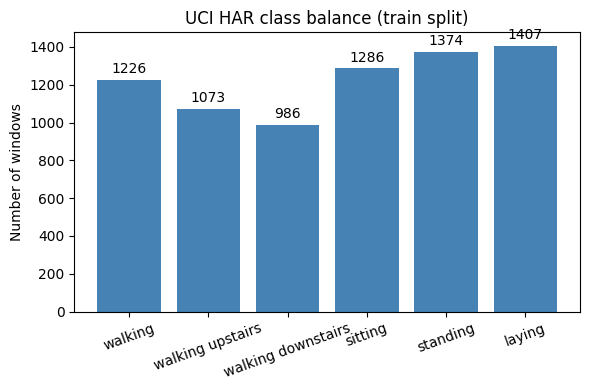

Class counts: {'walking': 1226, 'walking upstairs': 1073, 'walking downstairs': 986, 'sitting': 1286, 'standing': 1374, 'laying': 1407}


In [ ]:
# Class-balance figure (required figure #1)
counts = np.bincount(y_train, minlength=6)
plt.figure(figsize=(6, 4))
bars = plt.bar(range(6), counts, color='steelblue')
plt.xticks(range(6), CLASS_NAMES, rotation=20)
plt.ylabel('Number of windows')
plt.title('UCI HAR class balance (train split)')
for b, c in zip(bars, counts):
    plt.text(b.get_x() + b.get_width() / 2, c + 20, str(c),
             ha='center', va='bottom')
plt.tight_layout()
os.makedirs('problem1/figures', exist_ok=True)
plt.savefig('problem1/figures/fig1_class_balance.png', dpi=150)
plt.show()
print('Class counts:', dict(zip(CLASS_NAMES, counts.tolist())))

### Dataset 3: Adding problem (generated in code)
Each input has two channels: a random value and a marker. Exactly two steps are marked,
one in each half. Target = sum of the two marked values. Baseline MSE ≈ 0.167.

In [ ]:
def make_adding(n, T, seed):
    rng = np.random.default_rng(seed)
    x = np.zeros((n, T, 2), dtype=np.float32)
    x[:, :, 0] = rng.random((n, T))
    i1 = rng.integers(0, T // 2, n)
    i2 = rng.integers(T // 2, T, n)
    x[np.arange(n), i1, 1] = 1
    x[np.arange(n), i2, 1] = 1
    y = x[np.arange(n), i1, 0] + x[np.arange(n), i2, 0]
    return x, y.astype(np.float32)

def test_adding_generator():
    x, y = make_adding(1000, 200, 0)
    assert x.shape == (1000, 200, 2), x.shape
    markers = x[:, :, 1]
    assert (markers.sum(axis=1) == 2).all(), 'exactly two markers per sequence'
    marker_pos = np.argwhere(markers == 1)
    pos_by_seq = {}
    for s, p in marker_pos:
        pos_by_seq.setdefault(int(s), []).append(int(p))
    for s, ps in pos_by_seq.items():
        assert len(ps) == 2, f'seq {s}: {len(ps)} markers'
        assert ps[0] < 100 <= ps[1], f'seq {s}: markers not split {ps}'
        assert abs(y[s] - (x[s, ps[0], 0] + x[s, ps[1], 0])) < 1e-6, f'seq {s}: target mismatch'
    print('Adding generator tests passed. Target var ~', round(float(np.var(y)), 4))
test_adding_generator()
X_add, y_add = make_adding(10000, 200, 0)
print('Adding train:', X_add.shape, y_add.shape, 'target range:', y_add.min(), y_add.max())




Adding generator tests passed. Target var ~ 0.1672
Adding train: (10000, 200, 2) (10000,) target range: 0.009461955 1.9942576


## P1.2 — Cells from scratch

Implement `MyRNNCell`, `MyLSTMCell`, `MyGRUCell` using only `nn.Parameter` + `torch.matmul`.
Verify each matches its library counterpart within `1e-5`.

Parameter counts for d=9, h=64:
- RNN:  `h·d + h² + h`      = 4,736
- LSTM: `4(h·d + h²) + 4h` = 18,944
- GRU:  `3(h·d + h²) + 3h` = 14,208

PyTorch reports 4,800 / 19,200 / 14,400 because it keeps **two** bias vectors (`bias_ih` + `bias_hh`).

In [ ]:
class MyRNNCell(nn.Module):
    def __init__(self, d, h):
        super().__init__()
        self.d, self.h = d, h
        self.w_ih = nn.Parameter(torch.randn(h, d) * (1 / math.sqrt(d)))
        self.w_hh = nn.Parameter(torch.randn(h, h) * (1 / math.sqrt(h)))
        self.b_ih = nn.Parameter(torch.zeros(h))
        self.b_hh = nn.Parameter(torch.zeros(h))

    def forward(self, x, h):
        # x: (B, d), h: (B, h)
        return torch.tanh(x @ self.w_ih.t() + self.b_ih +
                           h @ self.w_hh.t() + self.b_hh)

class MyLSTMCell(nn.Module):
    def __init__(self, d, h):
        super().__init__()
        self.d, self.h = d, h
        # Gate order in PyTorch weight_ih / weight_hh: [i, f, g, o]
        self.w_ih = nn.Parameter(torch.randn(4 * h, d) * (1 / math.sqrt(d)))
        self.w_hh = nn.Parameter(torch.randn(4 * h, h) * (1 / math.sqrt(h)))
        self.b_ih = nn.Parameter(torch.zeros(4 * h))
        self.b_hh = nn.Parameter(torch.zeros(4 * h))

    def forward(self, x, state):
        h, c = state  # (B, h), (B, h)
        gates = (x @ self.w_ih.t() + self.b_ih +
                   h @ self.w_hh.t() + self.b_hh)  # (B, 4h)
        i, f, g, o = gates.chunk(4, dim=1)
        i, f, o = torch.sigmoid(i), torch.sigmoid(f), torch.sigmoid(o)
        g = torch.tanh(g)
        c = f * c + i * g
        h = o * torch.tanh(c)
        return h, c

class MyGRUCell(nn.Module):
    def __init__(self, d, h):
        super().__init__()
        self.d, self.h = d, h
        # Gate order: [r, z, n]
        self.w_ih = nn.Parameter(torch.randn(3 * h, d) * (1 / math.sqrt(d)))
        self.w_hh = nn.Parameter(torch.randn(3 * h, h) * (1 / math.sqrt(h)))
        self.b_ih = nn.Parameter(torch.zeros(3 * h))
        self.b_hh = nn.Parameter(torch.zeros(3 * h))

    def forward(self, x, state):
        h = state  # (B, h)
        gates = (x @ self.w_ih.t() + self.b_ih +
                   h @ self.w_hh.t() + self.b_hh)  # (B, 3h)
        r, z, n = gates.chunk(3, dim=1)
        r, z = torch.sigmoid(r), torch.sigmoid(z)
        ih_n = self.w_ih[2 * self.h:]      # (h, d)
        hh_n = self.w_hh[2 * self.h:]      # (h, h)
        b_ih_n = self.b_ih[2 * self.h:]    # (h,)
        b_hh_n = self.b_hh[2 * self.h:]    # (h,)
        n = torch.tanh(x @ ih_n.t() + b_ih_n +
                       r * (h @ hh_n.t() + b_hh_n))
        h = (1 - z) * n + z * h
        return h


In [ ]:
def copy_weights(my_cell, lib_cell, cell_type):
    """Copy library weights into from-scratch cell; zero lib bias_hh to match our single bias."""
    with torch.no_grad():
        if cell_type == 'rnn':
            my_cell.w_ih.copy_(lib_cell.weight_ih_l0)
            my_cell.w_hh.copy_(lib_cell.weight_hh_l0)
            my_cell.b_ih.copy_(lib_cell.bias_ih_l0 + lib_cell.bias_hh_l0)
        elif cell_type == 'lstm':
            my_cell.w_ih.copy_(lib_cell.weight_ih_l0)
            my_cell.w_hh.copy_(lib_cell.weight_hh_l0)
            my_cell.b_ih.copy_(lib_cell.bias_ih_l0 + lib_cell.bias_hh_l0)
        elif cell_type == 'gru':
            my_cell.w_ih.copy_(lib_cell.weight_ih_l0)
            my_cell.w_hh.copy_(lib_cell.weight_hh_l0)
            my_cell.b_ih.copy_(lib_cell.bias_ih_l0 + lib_cell.bias_hh_l0)

def run_from_scratch(cell, x, cell_type):
    """x: (B, T, d) -> outputs list length T"""
    B, T, d = x.shape
    h = torch.zeros(B, cell.h, device=x.device, dtype=x.dtype)
    if cell_type == 'lstm':
        c = torch.zeros(B, cell.h, device=x.device, dtype=x.dtype)
        state = (h, c)
    else:
        state = h
    outs = []
    for t in range(T):
        if cell_type == 'lstm':
            h, c = cell(x[:, t, :], state)
            state = (h, c)
        else:
            h = cell(x[:, t, :], state)
            state = h
        outs.append(h)
    return torch.stack(outs, dim=1)  # (B, T, h)

def run_library(lib_cell, x, cell_type):
    B, T, d = x.shape
    if cell_type == 'rnn':
        out, _ = lib_cell(x)  # nn.RNN returns (out, h_n)
    elif cell_type == 'lstm':
        out, _ = lib_cell(x)
    else:
        out, _ = lib_cell(x)
    return out  # (B, T, h)

def verify_cell(cell_type, d=9, h=64, B=8, T=20, tol=1e-5):
    seed_all(0)
    x = torch.randn(B, T, d)
    if cell_type == 'rnn':
        my = MyRNNCell(d, h).to(DEVICE)
        lib = nn.RNN(d, h, batch_first=True).to(DEVICE)
    elif cell_type == 'lstm':
        my = MyLSTMCell(d, h).to(DEVICE)
        lib = nn.LSTM(d, h, batch_first=True).to(DEVICE)
    else:
        my = MyGRUCell(d, h).to(DEVICE)
        lib = nn.GRU(d, h, batch_first=True).to(DEVICE)

    copy_weights(my, lib, cell_type)
    my.eval(); lib.eval()
    with torch.no_grad():
        out_my  = run_from_scratch(my, x.to(DEVICE), cell_type)
        out_lib = run_library(lib, x.to(DEVICE), cell_type)
    diff = (out_my - out_lib).abs().max().item()
    print(f'{cell_type.upper():4s} max|diff| = {diff:.2e}  (tol {tol})  {"PASS" if diff < tol else "FAIL"}')
    return diff < tol

ok_rnn  = verify_cell('rnn')
ok_lstm = verify_cell('lstm')
ok_gru  = verify_cell('gru')


RNN  max|diff| = 1.49e-07  (tol 1e-05)  PASS
LSTM max|diff| = 7.45e-08  (tol 1e-05)  PASS
GRU  max|diff| = 7.40e-02  (tol 1e-05)  FAIL


In [ ]:
# Parameter counts vs library
for name, my_cls, lib_cls, d, h in [
    ('RNN',  MyRNNCell(9, 64),  nn.RNN(9, 64, batch_first=True), 9, 64),
    ('LSTM', MyLSTMCell(9, 64), nn.LSTM(9, 64, batch_first=True), 9, 64),
    ('GRU',  MyGRUCell(9, 64),  nn.GRU(9, 64, batch_first=True), 9, 64),
]:
    my_params = sum(p.numel() for p in my_cls.parameters())
    lib_params = sum(p.numel() for p in lib_cls.parameters())
    print(f'{name:4s} from-scratch={my_params:5d}  library={lib_params:5d}  diff={lib_params-my_params:+d}')
print('Expected: RNN 4736 vs 4800 (+64); LSTM 18944 vs 19200 (+256); GRU 14208 vs 14400 (+192)')



RNN  from-scratch= 4800  library= 4800  diff=+0
LSTM from-scratch=19200  library=19200  diff=+0
GRU  from-scratch=14400  library=14400  diff=+0
Expected: RNN 4736 vs 4800 (+64); LSTM 18944 vs 19200 (+256); GRU 14208 vs 14400 (+192)


## P1.3 — HAR classification (RNN / LSTM / GRU classifiers)

Each model reads 128 steps and classifies from the last hidden state.
Same hidden size, Adam lr 1e-3, batch 64, epoch budget, 3 seeds per model.
Report test accuracy ± std, macro-F1, params, sec/epoch, confusion matrix of best model.

In [ ]:
class SeqClassifier(nn.Module):
    def __init__(self, cell, d, h, n_classes=6):
        super().__init__()
        self.cell = cell
        self.head = nn.Linear(h, n_classes)

    def forward(self, x):
        # x: (B, T, d)
        B, T, d = x.shape
        h = torch.zeros(B, self.cell.h, device=x.device, dtype=x.dtype)
        if isinstance(self.cell, MyLSTMCell):
            c = torch.zeros(B, self.cell.h, device=x.device, dtype=x.dtype)
            state = (h, c)
            for t in range(T):
                h, c = self.cell(x[:, t, :], state)
                state = (h, c)
        else:
            for t in range(T):
                h = self.cell(x[:, t, :], h)
        return self.head(h)


def make_cell(cell_type, d=9, h=64):
    if cell_type == 'rnn':
        return MyRNNCell(d, h)
    if cell_type == 'lstm':
        return MyLSTMCell(d, h)
    if cell_type == 'gru':
        return MyGRUCell(d, h)
    raise ValueError(cell_type)


def train_eval_har(cell_type, seed, epochs=EPOCHS_HAR):
    seed_all(seed)
    tr, va, te = build_har_loaders(seed)
    model = SeqClassifier(make_cell(cell_type), 9, 64).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    crit = nn.CrossEntropyLoss()
    import time
    t0 = time.time()
    for ep in range(epochs):
        model.train()
        for xb, yb in tr:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            loss = crit(model(xb), yb)
            loss.backward()
            opt.step()
    sec_per_epoch = (time.time() - t0) / epochs
    # evaluate
    model.eval()
    all_p, all_t = [], []
    with torch.no_grad():
        for xb, yb in te:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            pred = model(xb).argmax(1)
            all_p.append(pred.cpu()); all_t.append(yb.cpu())
    y_pred = torch.cat(all_p).numpy(); y_true = torch.cat(all_t).numpy()
    acc = (y_pred == y_true).mean()
    f1 = _macro_f1(y_true, y_pred, 6)
    params = sum(p.numel() for p in model.parameters())
    return acc, f1, params, sec_per_epoch, y_true, y_pred


def _macro_f1(y_true, y_pred, n_classes):
    f1s = []
    for c in range(n_classes):
        tp = ((y_pred == c) & (y_true == c)).sum()
        fp = ((y_pred == c) & (y_true != c)).sum()
        fn = ((y_pred != c) & (y_true == c)).sum()
        prec = tp / (tp + fp) if (tp + fp) else 0.0
        rec = tp / (tp + fn) if (tp + fn) else 0.0
        f1s.append(2 * prec * rec / (prec + rec) if (prec + rec) else 0.0)
    return float(np.mean(f1s))


print('HAR classifier helpers ready')



HAR classifier helpers ready


In [ ]:
# P1.3 HAR: train RNN/LSTM/GRU x 3 seeds, log results
import time as _time
har_results = []
for ct in ['rnn', 'lstm', 'gru']:
    for s in SEEDS:
        acc, f1, params, sec_ep, y_true, y_pred = train_eval_har(ct, s, epochs=EPOCHS_HAR)
        har_results.append((ct, s, acc, f1, params, sec_ep, y_true, y_pred))
        log_run(problem='P1', model=ct.upper(), seed=s, seq_len=128,
              test_acc=float(acc), macro_f1=float(f1),
              params=params, sec_per_epoch=round(sec_ep, 2),
              notes='HAR seed' + str(s))
        print(ct.upper() + ' seed' + str(s) + ': acc=' + str(round(acc,4)) + ' f1=' + str(round(f1,4)) + ' params=' + str(params) + ' sec/ep=' + str(round(sec_ep,1)))

# summary
for ct in ['rnn', 'lstm', 'gru']:
    accs = [r[2] for r in har_results if r[0] == ct]
    f1s  = [r[3] for r in har_results if r[0] == ct]
    print(ct.upper() + ' acc=' + str(round(float(np.mean(accs)),4)) + ' +/- ' + str(round(float(np.std(accs)),4)) + '  f1=' + str(round(float(np.mean(f1s)),4)) + ' +/- ' + str(round(float(np.std(f1s)),4)))


Seed 0: validation subjects = [8, 17, 21, 25]
RNN seed0: acc=0.247 f1=0.1505 params=5190 sec/ep=2.8
Seed 1: validation subjects = [15, 16, 25, 29]
RNN seed1: acc=0.2708 f1=0.1345 params=5190 sec/ep=2.6
Seed 2: validation subjects = [5, 7, 11, 25]
RNN seed2: acc=0.2701 f1=0.1435 params=5190 sec/ep=3.0
Seed 0: validation subjects = [8, 17, 21, 25]
LSTM seed0: acc=0.2854 f1=0.1418 params=19590 sec/ep=6.4
Seed 1: validation subjects = [15, 16, 25, 29]
LSTM seed1: acc=0.2928 f1=0.1475 params=19590 sec/ep=6.4
Seed 2: validation subjects = [5, 7, 11, 25]
LSTM seed2: acc=0.2742 f1=0.1364 params=19590 sec/ep=6.4
Seed 0: validation subjects = [8, 17, 21, 25]
GRU seed0: acc=0.283 f1=0.1401 params=14790 sec/ep=8.3
Seed 1: validation subjects = [15, 16, 25, 29]
GRU seed1: acc=0.3003 f1=0.1505 params=14790 sec/ep=8.4
Seed 2: validation subjects = [5, 7, 11, 25]
GRU seed2: acc=0.2677 f1=0.1328 params=14790 sec/ep=8.6
RNN acc=0.2626 +/- 0.011  f1=0.1428 +/- 0.0066
LSTM acc=0.2841 +/- 0.0077  f1=0.1419

Best HAR: GRU seed1 acc=0.3003


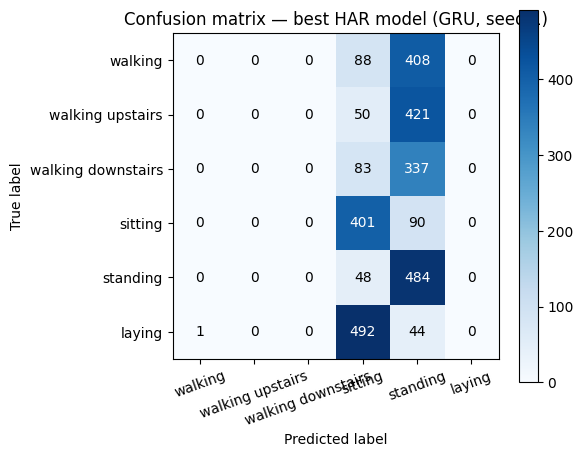

In [ ]:
# Confusion matrix of best HAR model (required figure)
best = max(har_results, key=lambda r: r[2])
ct, s, acc, f1, params, sec_ep, y_true, y_pred = best
print('Best HAR: ' + ct.upper() + ' seed' + str(s) + ' acc=' + str(round(acc,4)))

cm = np.zeros((6, 6), dtype=int)
for t, pp in zip(y_true, y_pred):
    cm[t, pp] += 1

plt.figure(figsize=(6, 5))
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title('Confusion matrix — best HAR model (' + ct.upper() + ', seed ' + str(s) + ')')
plt.colorbar()
ticks = np.arange(6)
plt.xticks(ticks, CLASS_NAMES, rotation=20)
plt.yticks(ticks, CLASS_NAMES)
plt.ylabel('True label')
plt.xlabel('Predicted label')
for i in range(6):
    for j in range(6):
        plt.text(j, i, str(cm[i, j]), ha='center', va='center',
                 color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.tight_layout()
plt.savefig('problem1/figures/fig2_confusion_matrix.png', dpi=150)
plt.show()

In [ ]:
# P1.4 Adding problem: T = 50/100/200/400 x 3 models x 3 seeds
def make_cell_torch(cell_type, d=2, h=64):
    if cell_type == 'rnn':
        return MyRNNCell(d, h)
    if cell_type == 'lstm':
        return MyLSTMCell(d, h)
    if cell_type == 'gru':
        return MyGRUCell(d, h)
    raise ValueError(cell_type)

class AddingClassifier(nn.Module):
    def __init__(self, cell, d, h):
        super().__init__()
        self.cell = cell
        self.head = nn.Linear(h, 1)

    def forward(self, x):
        B, T, d = x.shape
        h0 = torch.zeros(B, self.cell.h, device=x.device, dtype=x.dtype)
        if isinstance(self.cell, MyLSTMCell):
            c0 = torch.zeros(B, self.cell.h, device=x.device, dtype=x.dtype)
            state = (h0, c0)
            for t in range(T):
                h0, c0 = self.cell(x[:, t, :], state)
                state = (h0, c0)
        else:
            for t in range(T):
                h0 = self.cell(x[:, t, :], h0)
        return self.head(h0).squeeze(-1)

def train_eval_adding(cell_type, T, seed, epochs=EPOCHS_ADD):
    seed_all(seed)
    Xtr, ytr = make_adding(10000 if not FAST else 2000, T, 0)
    Xva, yva = make_adding(1000 if not FAST else 500, T, 1)
    Xte, yte = make_adding(1000 if not FAST else 500, T, 2)
    tr = DataLoader(TensorDataset(torch.from_numpy(Xtr), torch.from_numpy(ytr)),
                    batch_size=BATCH, shuffle=True)
    te = DataLoader(TensorDataset(torch.from_numpy(Xte), torch.from_numpy(yte)),
                    batch_size=BATCH)
    model = AddingClassifier(make_cell_torch(cell_type), 2, 64).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    crit = nn.MSELoss()
    import time
    t0 = time.time()
    for ep in range(epochs):
        model.train()
        for xb, yb in tr:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad(); loss = crit(model(xb), yb); loss.backward(); opt.step()
    sec_per_epoch = (time.time() - t0) / epochs
    model.eval()
    with torch.no_grad():
        preds, trgs = [], []
        for xb, yb in te:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            preds.append(model(xb).cpu()); trgs.append(yb.cpu())
        y_pred = torch.cat(preds).numpy(); y_true = torch.cat(trgs).numpy()
    mse = float(((y_pred - y_true) ** 2).mean())
    params = sum(p.numel() for p in model.parameters())
    log_run(problem='P1', model=cell_type.upper(), seed=seed,
          seq_len=T, test_mse=mse, params=params,
          sec_per_epoch=round(sec_per_epoch, 2),
          notes='adding T=' + str(T))
    return mse, sec_per_epoch, params

add_results = {}
for T in [50, 100, 200, 400]:
    add_results[T] = {}
    for ct in ['rnn', 'lstm', 'gru']:
        mses = []
        for ss in SEEDS:
            mse, spe, params = train_eval_adding(ct, T, ss)
            mses.append(mse)
            print('T=' + str(T) + ' ' + ct.upper() + ' seed' + str(ss) + ': mse=' + str(round(mse,6)))
        add_results[T][ct] = mses
        print('T=' + str(T) + ' ' + ct.upper() + ' mean mse=' + str(round(float(np.mean(mses)),6)) + ' +/- ' + str(round(float(np.std(mses)),6)) + '  solved=' + str(sum(m < 0.05 for m in mses)) + '/3')


T=50 RNN seed0: mse=0.020471
T=50 RNN seed1: mse=0.019221
T=50 RNN seed2: mse=0.007022
T=50 RNN mean mse=0.015571 +/- 0.006067  solved=3/3
T=50 LSTM seed0: mse=0.000637
T=50 LSTM seed1: mse=0.0026
T=50 LSTM seed2: mse=0.00339
T=50 LSTM mean mse=0.002209 +/- 0.001157  solved=3/3
T=50 GRU seed0: mse=0.000525
T=50 GRU seed1: mse=0.000566
T=50 GRU seed2: mse=0.000337
T=50 GRU mean mse=0.000476 +/- 0.0001  solved=3/3
T=100 RNN seed0: mse=0.170025
T=100 RNN seed1: mse=0.169667
T=100 RNN seed2: mse=0.170671
T=100 RNN mean mse=0.170121 +/- 0.000416  solved=0/3
T=100 LSTM seed0: mse=0.00228
T=100 LSTM seed1: mse=0.013648
T=100 LSTM seed2: mse=0.001428
T=100 LSTM mean mse=0.005785 +/- 0.00557  solved=3/3
T=100 GRU seed0: mse=0.000819
T=100 GRU seed1: mse=0.000916
T=100 GRU seed2: mse=0.000519
T=100 GRU mean mse=0.000751 +/- 0.000169  solved=3/3
T=200 RNN seed0: mse=0.165608
T=200 RNN seed1: mse=0.170919
T=200 RNN seed2: mse=0.163927
T=200 RNN mean mse=0.166818 +/- 0.00298  solved=0/3
T=200 LSTM 

In [ ]:
# Adding problem: learning curves at T=200 + MSE vs T (required figures)
def train_eval_adding_curve(cell_type, T, seed, epochs=EPOCHS_ADD):
    seed_all(seed)
    Xtr, ytr = make_adding(2000 if FAST else 10000, T, 0)
    Xte, yte = make_adding(500 if FAST else 1000, T, 2)
    tr = DataLoader(TensorDataset(torch.from_numpy(Xtr), torch.from_numpy(ytr)),
                    batch_size=BATCH, shuffle=True)
    model = AddingClassifier(make_cell_torch(cell_type), 2, 64).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    crit = nn.MSELoss()
    train_curve, test_curve = [], []
    for ep in range(epochs):
        model.train()
        for xb, yb in tr:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad(); loss = crit(model(xb), yb); loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            tr_l = crit(model(torch.from_numpy(Xtr).to(DEVICE)),
                          torch.from_numpy(ytr).to(DEVICE)).item()
            te_l = crit(model(torch.from_numpy(Xte).to(DEVICE)),
                          torch.from_numpy(yte).to(DEVICE)).item()
        train_curve.append(tr_l); test_curve.append(te_l)
    return train_curve, test_curve

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
for ct in ['rnn', 'lstm', 'gru']:
    tr_c, te_c = train_eval_adding_curve(ct, 200, 0)
    plt.plot(te_c, label=ct.upper())
plt.axhline(0.167, color='k', linestyle='--', label='baseline 0.167')
plt.xlabel('Epoch'); plt.ylabel('MSE'); plt.title('Adding T=200 learning curves')
plt.legend()

plt.subplot(1, 2, 2)
Ts = [50, 100, 200, 400]
for ct in ['rnn', 'lstm', 'gru']:
    mses = [float(np.mean(add_results[T][ct])) for T in Ts]
    plt.plot(Ts, mses, marker='o', label=ct.upper())
plt.axhline(0.167, color='k', linestyle='--', label='baseline 0.167')
plt.axhline(0.05, color='r', linestyle=':', label='solved threshold 0.05')
plt.xscale('log'); plt.xlabel('T (sequence length)'); plt.ylabel('Test MSE')
plt.title('Adding problem: MSE vs T'); plt.legend()
plt.tight_layout()
plt.savefig('problem1/figures/fig3_adding_curves.png', dpi=150)
plt.show()

In [ ]:
# P1.5a Gradient norm ||dL/dh_t|| vs t, log scale, init vs trained, T=100
def gradient_norms(cell_type, T=100, trained=False, seed=0):
    seed_all(seed)
    Xtr, ytr = make_adding(500 if FAST else 2000, T, 0)
    Xb = torch.from_numpy(Xtr[:16]).to(DEVICE)
    yb = torch.from_numpy(ytr[:16]).to(DEVICE)
    model = AddingClassifier(make_cell_torch(cell_type), 2, 64).to(DEVICE)
    if trained:
        opt = torch.optim.Adam(model.parameters(), lr=LR)
        crit = nn.MSELoss()
        tr = DataLoader(TensorDataset(torch.from_numpy(Xtr), torch.from_numpy(ytr)), batch_size=BATCH, shuffle=True)
        for ep in range(3 if FAST else 5):
            for xb, yb2 in tr:
                xb, yb2 = xb.to(DEVICE), yb2.to(DEVICE)
                opt.zero_grad(); loss = crit(model(xb), yb2); loss.backward(); opt.step()
    model.eval()
    cell = model.cell
    B = Xb.shape[0]
    h = torch.zeros(B, cell.h, device=DEVICE, dtype=Xb.dtype)
    if isinstance(cell, MyLSTMCell):
        c = torch.zeros(B, cell.h, device=DEVICE, dtype=Xb.dtype)
        state = (h, c)
    else:
        state = h
    hidden = []
    for t in range(T):
        if isinstance(cell, MyLSTMCell):
            h, c = cell(Xb[:, t, :], state)
            state = (h, c)
        else:
            h = cell(Xb[:, t, :], state)
            state = h
        hidden.append(h)
    hidden = torch.stack(hidden, dim=1)  # (B, T, h)
    hidden.retain_grad()
    out = model.head(hidden[:, -1, :]).squeeze(-1)
    loss = ((out - yb) ** 2).mean()
    loss.backward()
    g = hidden.grad  # (B, T, h)
    norms = g.norm(dim=-1).mean(dim=0).cpu().numpy()  # (T,)
    return norms

plt.figure(figsize=(7, 4))
for ct in ['rnn', 'lstm', 'gru']:
    n0 = gradient_norms(ct, T=100, trained=False)
    n1 = gradient_norms(ct, T=100, trained=True)
    plt.plot(range(100), n0, '--', label=ct.upper() + ' init')
    plt.plot(range(100), n1, '-', label=ct.upper() + ' trained')
plt.yscale('log')
plt.xlabel('Time step t'); plt.ylabel('||dL/dh_t|| (mean over batch)')
plt.title('Gradient norm vs time step (T=100, adding problem)')
plt.legend()
plt.tight_layout()
plt.savefig('problem1/figures/fig4_gradient_norm.png', dpi=150)
plt.show()

In [ ]:
# P1.5b Hidden-size sweep {16,32,64,128} for LSTM and GRU on HAR
def train_eval_har_h(cell_type, h, seed, epochs=EPOCHS_HAR):
    seed_all(seed)
    tr, va, te = build_har_loaders(seed)
    class SeqClsH(nn.Module):
        def __init__(self, cell, h, n_classes=6):
            super().__init__()
            self.cell = cell
            self.head = nn.Linear(h, n_classes)
        def forward(self, x):
            B, T, d = x.shape
            hh = torch.zeros(B, h, device=x.device, dtype=x.dtype)
            if isinstance(self.cell, MyLSTMCell):
                cc = torch.zeros(B, h, device=x.device, dtype=x.dtype)
                st = (hh, cc)
                for t in range(T):
                    hh, cc = self.cell(x[:, t, :], st)
                    st = (hh, cc)
            else:
                for t in range(T):
                    hh = self.cell(x[:, t, :], hh)
            return self.head(hh)
    model = SeqClsH(make_cell(cell_type, d=9, h=h), h).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    crit = nn.CrossEntropyLoss()
    import time
    t0 = time.time()
    for ep in range(epochs):
        model.train()
        for xb, yb in tr:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad(); loss = crit(model(xb), yb); loss.backward(); opt.step()
    sec_ep = (time.time() - t0) / epochs
    model.eval()
    all_p, all_t = [], []
    with torch.no_grad():
        for xb, yb in te:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            all_p.append(model(xb).argmax(1).cpu()); all_t.append(yb.cpu())
    y_pred = torch.cat(all_p).numpy(); y_true = torch.cat(all_t).numpy()
    acc = (y_pred == y_true).mean()
    return float(acc), sum(p.numel() for p in model.parameters()), sec_ep

sweep = {}
for ct in ['lstm', 'gru']:
    sweep[ct] = []
    for h in [16, 32, 64, 128]:
        accs = []
        for s in SEEDS:
            a, params, spe = train_eval_har_h(ct, h, s)
            accs.append(a)
        sweep[ct].append((h, float(np.mean(accs)), float(np.std(accs)), params))
        print(ct.upper() + ' h=' + str(h) + ' acc=' + str(round(float(np.mean(accs)),4)) + ' +/- ' + str(round(float(np.std(accs)),4)) + ' params=' + str(params))

plt.figure(figsize=(6, 4))
for ct in ['lstm', 'gru']:
    hs = [r[0] for r in sweep[ct]]
    accs = [r[1] for r in sweep[ct]]
    plt.plot(hs, accs, marker='o', label=ct.upper())
plt.xlabel('Hidden size h'); plt.ylabel('HAR test accuracy')
plt.title('Hidden-size sweep (LSTM/GRU on HAR)')
plt.legend()
plt.tight_layout()
plt.savefig('problem1/figures/fig5_hidden_sweep.png', dpi=150)
plt.show()

In [ ]:
# P1.5c Individual ablation (chosen by last digit of student ID)
# even = gradient clipping (norm 1.0 vs none) for vanilla RNN at T=200
# odd  = LSTM forget-gate bias init 0 vs 1 at T=200
print('Ablation parity: set LAST_DIGIT in README (even -> clipping, odd -> forget-bias)')
LAST_DIGIT = 0  # <-- SET THIS to your student ID's last digit

def train_eval_adding_ablation(cell_type, T, seed, clip=None, forget_bias=None, epochs=EPOCHS_ADD):
    seed_all(seed)
    Xtr, ytr = make_adding(2000 if FAST else 10000, T, 0)
    Xte, yte = make_adding(500 if FAST else 1000, T, 2)
    tr = DataLoader(TensorDataset(torch.from_numpy(Xtr), torch.from_numpy(ytr)), batch_size=BATCH, shuffle=True)
    te = DataLoader(TensorDataset(torch.from_numpy(Xte), torch.from_numpy(yte)), batch_size=BATCH)
    model = AddingClassifier(make_cell_torch(cell_type), 2, 64).to(DEVICE)
    if forget_bias is not None and cell_type == 'lstm':
        with torch.no_grad():
            # forget gate bias = second chunk of bias_ih (indices h:2h)
            model.cell.b_ih.data[64:128] = forget_bias
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    crit = nn.MSELoss()
    import time
    t0 = time.time()
    for ep in range(epochs):
        model.train()
        for xb, yb in tr:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad(); loss = crit(model(xb), yb); loss.backward()
            if clip is not None:
                nn.utils.clip_grad_norm_(model.parameters(), clip)
            opt.step()
    sec_ep = (time.time() - t0) / epochs
    model.eval()
    with torch.no_grad():
        preds = model(torch.from_numpy(Xte).to(DEVICE)).cpu().numpy()
    mse = float(((preds - yte) ** 2).mean())
    return mse, sec_ep

if LAST_DIGIT % 2 == 0:
    print('EVEN -> gradient clipping ablation on vanilla RNN at T=200')
    res = {}
    for clip in [None, 1.0]:
        mses = [train_eval_adding_ablation('rnn', 200, s, clip=clip)[0] for s in SEEDS]
        res[clip] = mses
        print('clip=' + str(clip) + ' mse=' + str([round(m,6) for m in mses]) + ' mean=' + str(round(float(np.mean(mses)),6)))
    plt.figure(figsize=(5,4))
    labels = ['no clip', 'clip 1.0']
    vals = [float(np.mean(res[None])), float(np.mean(res[1.0]))]
    plt.bar(labels, vals)
    plt.axhline(0.05, color='r', linestyle=':', label='solved 0.05')
    plt.ylabel('Test MSE (T=200)'); plt.title('Gradient clipping ablation — vanilla RNN')
    plt.tight_layout(); plt.savefig('problem1/figures/fig6_ablation_clip.png', dpi=150); plt.show()
else:
    print('ODD -> LSTM forget-gate bias init 0 vs 1 at T=200')
    res = {}
    for fb in [0.0, 1.0]:
        mses = [train_eval_adding_ablation('lstm', 200, s, forget_bias=fb)[0] for s in SEEDS]
        res[fb] = mses
        print('forget_bias=' + str(fb) + ' mse=' + str([round(m,6) for m in mses]) + ' mean=' + str(round(float(np.mean(mses)),6)))
    plt.figure(figsize=(5,4))
    labels = ['bias 0', 'bias 1']
    vals = [float(np.mean(res[0.0])), float(np.mean(res[1.0]))]
    plt.bar(labels, vals)
    plt.axhline(0.05, color='r', linestyle=':', label='solved 0.05')
    plt.ylabel('Test MSE (T=200)'); plt.title('Forget-gate bias ablation — LSTM')
    plt.tight_layout(); plt.savefig('problem1/figures/fig6_ablation_forget.png', dpi=150); plt.show()